# Spectral modularity community detection on the Karate Club graph

This notebook implements spectral modularity partitioning from scratch on Zachary's Karate Club network (34 nodes, 78 edges). It draws the communities found after each split and tracks four node-level network metrics across the iterations.

The modularity matrix, the leading-eigenvector bipartition and the recursive bisection follow the method of Newman (2006) [1], as described in the course handout.

In [1]:

#Importing necessary libraries

import matplotlib.pyplot as plt
import numpy as np
import networkx as nx

## 1. Adjacency matrix, degrees and modularity matrix

For an undirected graph with adjacency matrix $A$, degree vector $k$ and $m$ edges, the modularity matrix is $B = A - \frac{k k^{\top}}{2m}$ [1]. For a split described by a vector $s \in \{-1,+1\}^n$, the modularity is $Q = \frac{1}{4m}\, s^{\top} B s$ [1].

In [2]:
#Intittializing the Adjacency matrix
A = nx.to_numpy_array(nx.karate_club_graph(),weight=None, dtype=int)

#defining the degree vectors

K=A.sum(axis=1).reshape(-1, 1)
Kt=np.transpose(K)
D=K@Kt

#number of edges
m=int(A.sum()/2)
print(m)

78


In [3]:
#Initializing the Modularity Matrix

B=A-D/(2*m)

## 2. Two-way split from the leading eigenvector

If $s$ is relaxed to real values of fixed length, $s^{\top} B s$ is maximised by the eigenvector of $B$ with the largest eigenvalue (Rayleigh–Ritz) [1]. Each node is assigned to one of two communities by the sign of its entry in that eigenvector.

In [4]:
#Now our goal is to Maximize Qv by varying s and find the s resulting in the maximum Qvm, which we will use leading eigenvector for.

#Finding Leading Eigenvector of B

EVal,EVec=np.linalg.eigh(B)

EVec=EVec.tolist()
EVal=EVal.tolist()

LVal=max(EVal)
ind=EVal.index(LVal)
LVec=[row[ind] for row in EVec]

print(LVal,LVec)

4.977080225729889 [0.387542930321193, 0.2695574218932876, 0.13189899082753725, 0.2534523569522071, 0.13400323139230153, 0.14573804098533003, 0.14573804098533005, 0.20935953611336922, -0.05447571362472031, -0.047852376909153664, 0.13400323139230155, 0.07784278925909417, 0.1287439647029672, 0.13502860919769785, -0.13943288264641318, -0.13943288264641318, 0.05851821196226572, 0.13197981066297848, -0.13943288264641318, 0.057648883747307145, -0.13943288264641318, 0.13197981066297848, -0.13943288264641324, -0.21674712434353907, -0.05633049671504986, -0.07540038590340689, -0.11580256794135774, -0.10276486676895015, -0.06834027295276417, -0.20629456129341386, -0.09626390562457682, -0.101856779081365, -0.32390453333971986, -0.3698378633280628]


In [5]:
#Now lets convert the leading eigenvector to have elements in -1 or 1 for assignment.
u1=list()
for i in LVec:
  if i>0:
    u1.append(1)
  else:
    u1.append(-1)

u=np.array(u1)
ut=u.T
Q=ut@B@u

#We can now find the modularity by taking 1/4m of the Q value

Modularity = Q.item()/(4*m)

print(Modularity)
print(u1)

0.37146614069691
[1, 1, 1, 1, 1, 1, 1, 1, -1, -1, 1, 1, 1, 1, -1, -1, 1, 1, -1, 1, -1, 1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1]


## 3. A reusable function for any community

`Modul` rebuilds the modularity matrix from whatever adjacency matrix it receives and returns, depending on `choice`: the matrix (`"ModMat"`), the modularity of the split (`"Mod"`), the $\pm 1$ split vector (`"div"` or `"Evec"`), or the leading eigenvalue (`"Eigen"`).

In [6]:
#Let us now make the function to achieve each step to call recursively

def Modul(A,choice):
  K=A.sum(axis=1).reshape(-1, 1)
  Kt=np.transpose(K)
  D=K@Kt
  m=int(A.sum()/2)
  B=A-D/(2*m)
  EVal,EVec=np.linalg.eigh(B)
  EVec=EVec.tolist()
  EVal=EVal.tolist()
  LVal=max(EVal)
  ind=EVal.index(LVal)
  LVec=[row[ind] for row in EVec]
  u1=list()
  for i in LVec:
    if i>0:
      u1.append(1)
    else:
      u1.append(-1)
  u=np.array(u1)
  ut=u.T
  Q=ut@B@u
  Modularity = Q.item()/(4*m)
  if choice=="ModMat":
    return B
  elif choice=="Mod":
    return Modularity
  elif choice=="div":
    return u1
  elif choice=="Eigen":
    return LVal
  elif choice=="Evec":
    return u1
  else:
    print("Error, put correct term, returning None")
    return None


## 4. Recursive bisection

Each community is split by the signs of the leading eigenvector of its modularity matrix, and a community whose leading eigenvalue is not positive is left whole, which is the stopping rule of [1]. Here the modularity matrix is recomputed for each community's induced subgraph, as in the recursive procedure of the handout (Section 4). This differs from the generalized modularity matrix that Newman [1] uses when subdividing a network.

`Community_split` splits both the adjacency matrix and the list of original node IDs, so every community can be traced back to the 34 nodes. `Iteration[i]` holds the matrices of all communities after iteration `i`, and `Iteration_ids[i]` holds the matching node IDs. Iteration 0 is the full graph.

In [7]:
#Now we recursivelty split into communities, so let us create a function which simply takes the u and splits it into two communities.

#For this we would need a function which has both the orignal communities and the split (O is orignal community, u is the eigenvalue split)
def Community_split(O, v, ids):
  C1=list()
  C2=list()
  ids1=list()
  ids2=list()
  Count=0
  for i in v:
    if i==1:
      C1.append(O[Count,:])
      ids1.append(ids[Count])
    else:
      C2.append(O[Count,:])
      ids2.append(ids[Count])
    Count+=1
  C1=np.array(C1)
  C2=np.array(C2)
  C1new=list()
  C2new=list()
  Count=0
  for i in v:
    if i==1:
      C1new.append(C1[:,Count])
    else:
      C2new.append(C2[:,Count])
    Count+=1
  return (np.array(C1new), ids1), (np.array(C2new), ids2)

In [8]:
#Each community is stored as a matrix (listc) together with the list of original node IDs it contains (idsc).
#The IDs are needed later so that Graphing knows which nodes of the full graph belong to which community.
listc = [A]
idsc = [list(range(len(A)))]
listfinal = []
idsfinal = []
Iteration = {0: listc}
Iteration_ids = {0: idsc}
I = 0
while listc:
    listcnew = []
    idsnew = []
    for mat, ids in zip(listc, idsc):
        #the same +1/-1 vector from Modul splits both the matrix and its node IDs
        (a, ia), (b, ib) = Community_split(mat, Modul(mat, "div"), ids)
        listcnew.extend([a, b])
        idsnew.extend([ia, ib])
    listc = []
    idsc = []
    for mat, ids in zip(listcnew, idsnew):
        #a community whose leading eigenvalue is not positive cannot be split further
        if Modul(mat, "Eigen") <= 1e-10:
            listfinal.append(mat)
            idsfinal.append(ids)
        else:
            listc.append(mat)
            idsc.append(ids)
    I += 1
    #the snapshot of each iteration = communities still being split + communities that are finished
    #matrices and IDs are combined in the same order so they stay matched
    Iteration[I] = listc + listfinal
    Iteration_ids[I] = idsc + idsfinal

for i, j in Iteration.items():
  print(i)
  print(Iteration_ids[i])
  for a in j:
    print(a)
  print("\n\n")

0
[[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33]]
[[0 1 1 ... 1 0 0]
 [1 0 1 ... 0 0 0]
 [1 1 0 ... 0 1 0]
 ...
 [1 0 0 ... 0 1 1]
 [0 0 1 ... 1 0 1]
 [0 0 0 ... 1 1 0]]



1
[[0, 1, 2, 3, 4, 5, 6, 7, 10, 11, 12, 13, 16, 17, 19, 21], [8, 9, 14, 15, 18, 20, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33]]
[[0 1 1 1 1 1 1 1 1 1 1 1 0 1 1 1]
 [1 0 1 1 0 0 0 1 0 0 0 1 0 1 1 1]
 [1 1 0 1 0 0 0 1 0 0 0 1 0 0 0 0]
 [1 1 1 0 0 0 0 1 0 0 1 1 0 0 0 0]
 [1 0 0 0 0 0 1 0 1 0 0 0 0 0 0 0]
 [1 0 0 0 0 0 1 0 1 0 0 0 1 0 0 0]
 [1 0 0 0 1 1 0 0 0 0 0 0 1 0 0 0]
 [1 1 1 1 0 0 0 0 0 0 0 0 0 0 0 0]
 [1 0 0 0 1 1 0 0 0 0 0 0 0 0 0 0]
 [1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]
 [1 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0]
 [1 1 1 1 0 0 0 0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 1 1 0 0 0 0 0 0 0 0 0]
 [1 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0]
 [1 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0]
 [1 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0]]
[[0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 1 1]
 [0 0 0 0 0 0

## 5. Sanity checks

Checks the properties of $B$ proved in the handout (symmetric, rows sum to zero, the trivial partition has $Q = 0$) and that $Q$ from the matrix form agrees with the definition of modularity.

In [9]:
#Before moving on let us ensure all our operations align with the facts we are sure of

def ModularitySanitycheck(Modul):
    n = A.shape[0]
    m = A.sum() / 2
    B = Modul(A, "ModMat")
    s = Modul(A, "div")
    s_arr = np.array(s)

    print("B is symmetric:", np.allclose(B, B.T))
    print("every row of B sums to 0:", np.allclose(B.sum(axis=1), 0))

    ones = np.ones(n)
    print("trivial partition gives Q = 0:", np.isclose(ones @ B @ ones / (4*m), 0))

    print("labels are +1/-1, one per node:", len(s) == n and set(s) <= {1, -1})

    k = A.sum(axis=1)
    same = s_arr[:, None] == s_arr[None, :]
    Q_def = ((A - np.outer(k, k) / (2*m)) * same).sum() / (2*m)
    print("Modul's Q matches the definition (%.4f):" % Q_def, np.isclose(Modul(A, "Mod"), Q_def))

    print("flipping every sign leaves Q unchanged:", np.isclose(s_arr @ B @ s_arr, (-s_arr) @ B @ (-s_arr)))
    print("leading eigenvalue >= 0:", Modul(A, "Eigen") >= -1e-10)

ModularitySanitycheck(Modul)

B is symmetric: True
every row of B sums to 0: True
trivial partition gives Q = 0: True
labels are +1/-1, one per node: True
Modul's Q matches the definition (0.3715): True
flipping every sign leaves Q unchanged: True
leading eigenvalue >= 0: True


## 6. Visualization and node metrics

After each iteration, degree centrality, betweenness centrality, closeness centrality and the clustering coefficient are computed with NetworkX on the full node set with the edges between different communities removed (`Iteration_Graph`). The results are stored in `Metrics`, a dictionary keyed by iteration number, and plotted for every node across iterations. The community drawings use a fixed spring layout and one color per community.

In [10]:
#Now that our iterations are done, let us try to get a program Such that we can compute Node metrics and visualize it

def Node_Metric(Graph):
    DegCen=nx.degree_centrality(Graph)
    BwCen=nx.betweenness_centrality(Graph)
    ClCen=nx.closeness_centrality(Graph)
    CluCo=nx.clustering(Graph)
    return DegCen,BwCen,ClCen,CluCo

#We also add another function to build a graph after each iteration without intergraph edges, in order to colaculate the metrics.

def Iteration_Graph(A0, groups):
    M = np.zeros_like(A0)
    for ids in groups:
        M[np.ix_(ids, ids)] = A0[np.ix_(ids, ids)]
    return nx.from_numpy_array(M)



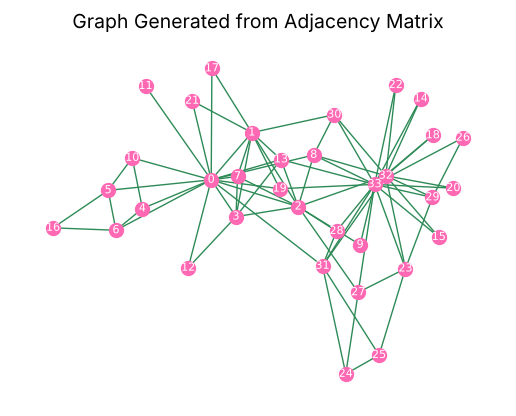

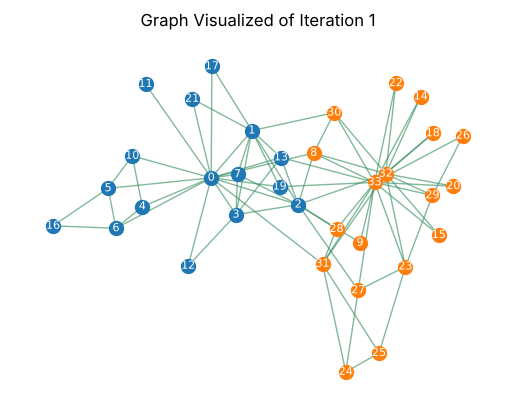

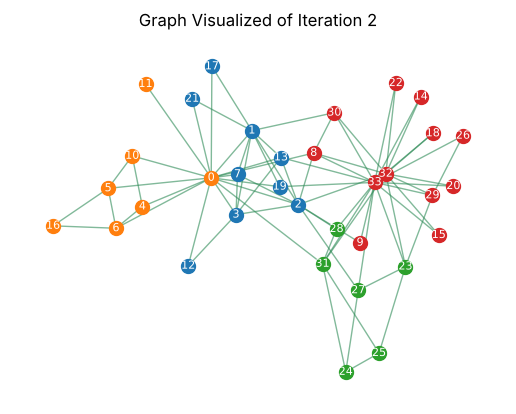

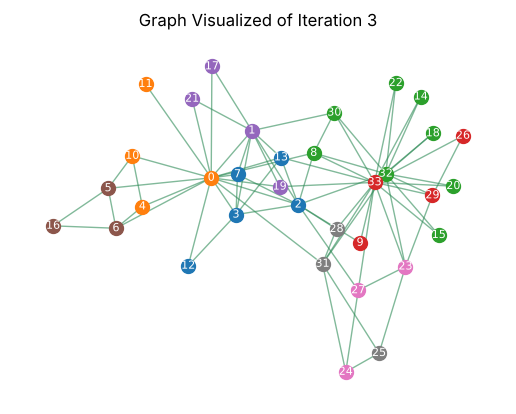

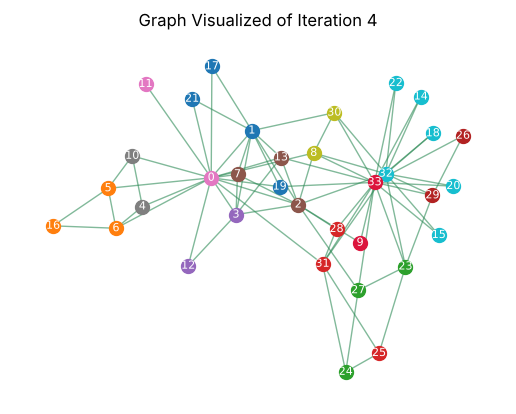

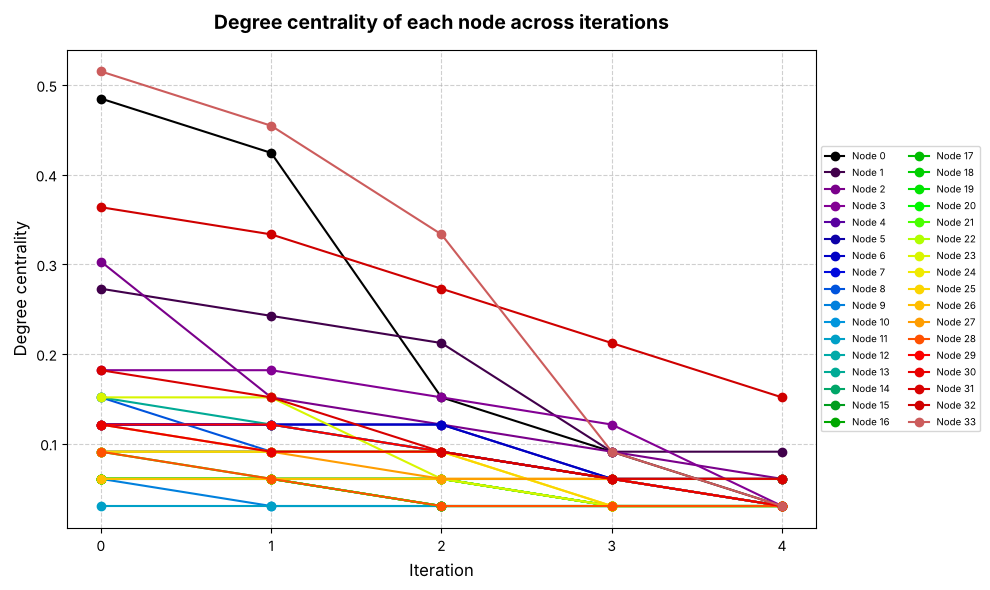

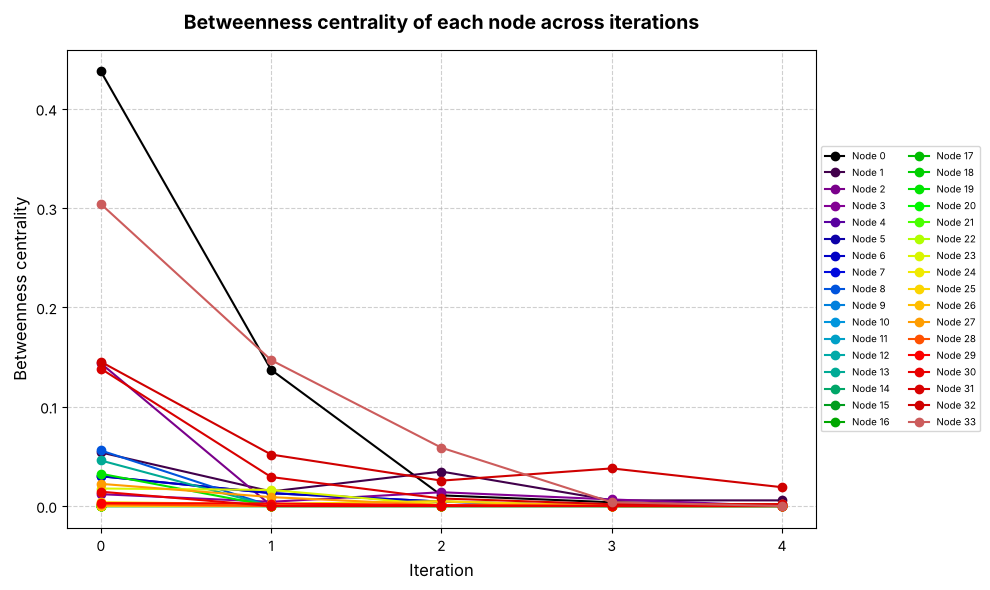

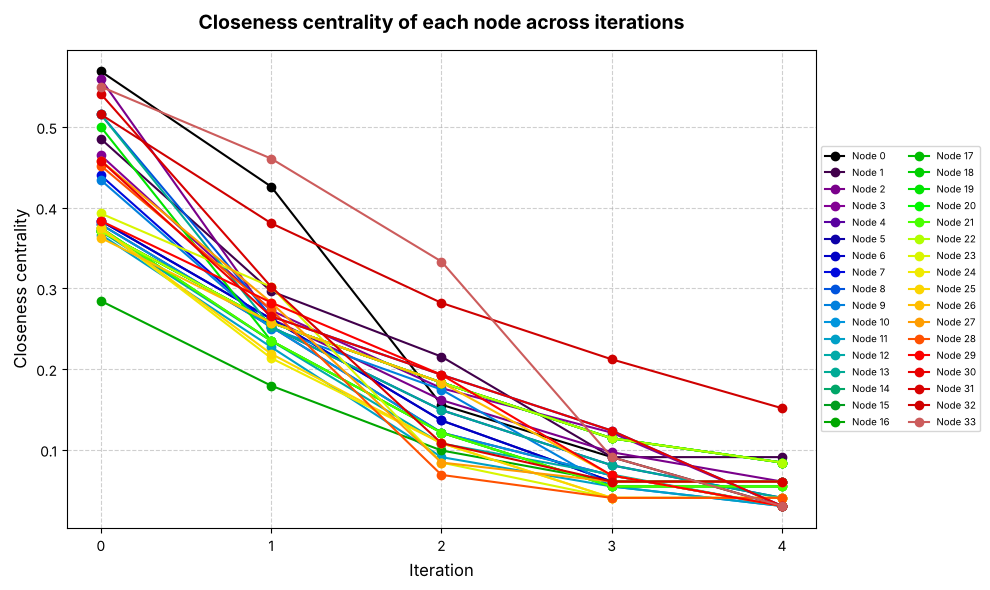

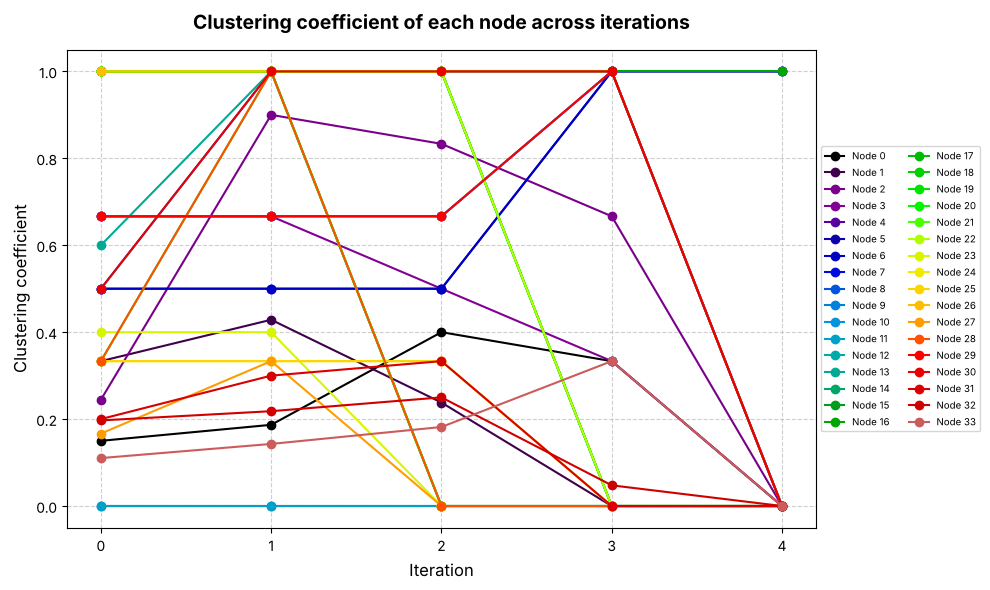

In [11]:
def Graphing(LI, LI_ids):
    colours = [
    'tab:blue', 'tab:orange', 'tab:green', 'tab:red', 'tab:purple',
    'tab:brown', 'tab:pink', 'tab:gray', 'tab:olive', 'tab:cyan',
    'crimson', 'firebrick', 'darkred', 'tomato', 'salmon', 'hotpink', 'deeppink', 'maroon',
    'darkorange', 'coral', 'gold', 'goldenrod', 'khaki',
    'forestgreen', 'limegreen', 'seagreen', 'olive', 'darkgreen', 'lightgreen',
    'navy', 'royalblue', 'steelblue', 'skyblue', 'dodgerblue', 'teal', 'turquoise',
    'indigo', 'violet', 'orchid', 'chocolate', 'sienna']
    A0 = LI[0][0]
    G = nx.from_numpy_array(A0)
    pos = nx.spring_layout(G, seed=7)
    ListDC=[]
    ListBC=[]
    ListCC=[]
    ListCO=[]
    Metrics = {}
    for i in LI.keys():
        A1,A2,A3,A4 = Node_Metric(Iteration_Graph(A0, LI_ids[i]))
        Metrics[i] = {"degree": A1, "betweenness": A2, "closeness": A3, "clustering": A4}
        ListDC.append([A1[n] for n in sorted(A1)])
        ListBC.append([A2[n] for n in sorted(A2)])
        ListCC.append([A3[n] for n in sorted(A3)])
        ListCO.append([A4[n] for n in sorted(A4)])
        if i == 0:
            nx.draw_networkx_nodes(G, pos, node_color="hotpink", node_size=100)
            nx.draw_networkx_edges(G, pos, width=1, edge_color="seagreen")
            nx.draw_networkx_labels(G, pos, font_size=8, font_family="Georgia", font_weight="normal", font_color="white")
            plt.title("Graph Generated from Adjacency Matrix", fontsize=14)
            plt.axis("off")
            plt.show()
        else:
            for c, j in enumerate(LI_ids[i]):
                nx.draw_networkx_nodes(G, pos, nodelist=j, node_color=colours[c], node_size=100)
            nx.draw_networkx_edges(G, pos, width=1, edge_color="seagreen", alpha=0.6)
            nx.draw_networkx_labels(G, pos, font_size=8, font_family="Georgia", font_weight="normal", font_color="white")
            plt.title(f"Graph Visualized of Iteration {i}")
            plt.axis("off")
            plt.show()

    DC=np.array(ListDC)
    BC=np.array(ListBC)
    CC=np.array(ListCC)
    CO=np.array(ListCO)
    Iter=np.arange(len(ListDC))

    def MakeMyGraph(Data, Iter, name):
        plt.figure(figsize=(10, 6))
        cmap = plt.get_cmap("nipy_spectral")
        for n in range(Data.shape[1]):
            plt.plot(Iter, Data[:, n], color=cmap(n / Data.shape[1]), marker="o", linewidth=1.5, label=f"Node {n}")
        plt.title(f"{name} of each node across iterations", fontsize=14, fontweight="bold", pad=15)
        plt.xlabel("Iteration", fontsize=12)
        plt.ylabel(name, fontsize=12)
        plt.xticks(Iter)
        plt.grid(True, linestyle="--", alpha=0.6)
        plt.legend(loc="center left", bbox_to_anchor=(1, 0.5), ncol=2, fontsize=7)
        plt.tight_layout()
        plt.show()
    MakeMyGraph(DC, Iter, "Degree centrality")
    MakeMyGraph(BC, Iter, "Betweenness centrality")
    MakeMyGraph(CC, Iter, "Closeness centrality")
    MakeMyGraph(CO, Iter, "Clustering coefficient")
    return DC, BC, CC, CO, Metrics

DC, BC, CC, CO, Metrics = Graphing(Iteration, Iteration_ids)


## Discussions
Let us individually analyze each metric and then look at some independant nodes and how they behave after iterations.

1. **Degree Centrality** of all the nodes consistently decrease as the splits are made since we remove the edges between communities. This means that nodes which were once very connected lose this aspect based on the partitioning. We can see in the Degree Centrality graph that nodes 0 and 32 which were once on top of the graph crash down to incredibly low values as the partition takes place and the same be observed in the Visualization as well.

2. **Betweenness Centrality** also suffers as a result of partitioning as we restrict the amount of path's available by removing inter community edges. 0 and 33 again suffer similar fate as they crash with increased partitions. However, this trend is not independant of outliers like 32 which increased its betweenness from iteration 2 to 3 as it became the sole connector of certain nodes inside its community.

3. **Closeness Centrality** decreases for every node without exception as it represents how near a node is to other node and narutally the more disconnected a graph gets, the lower the centrality will be. 33, 0 lead initially but after iteration 3, 32 remains on top by a wide margin (as it still remains quite connected in its community, evident from its Betweenness Centrality as well)

4. **Clustering Coefficient** differs as it does not decrease all the time and instead moves rather sporadically. It measures how many of a nodes neighbours are connected to each other, so a partition can either remove a node's unconnected neighbour or disconnect already connected ones leading in the value increasing and decreasing respectively. However, as the iterating stops, we notice all nodes' coefficient collapses to 0.0 for most of the nodes as communities shrink to increasingly smaller groups and probability of connected neighbours also shrinks.

5. **Nodes 0 and 33** are the central nodes in the intial iterations but end up losing their centrality quite a bit by iteration 3. They dont have high clustering values since they more so connect unlinked groups which is also the reasoning for their fall in other metrics.

6. **Node 32** is consistently the top performer for every metric past iteration 3 as while it is not a great central node initally, it gets relatively stronger to toh as the community shrinks 




## References

[1] M. E. J. Newman, "Modularity and community structure in networks," *Proceedings of the National Academy of Sciences* **103**(23): 8577–8582 (2006). https://doi.org/10.1073/pnas.0601602103

## The Unstreamlined Orignal File

Alongside this streamlined file, I have also the file I was orignally working on where I have some cells which simply contained older versions of certain function, which give deeper insight into the process and evolution of thought I went through to reach to these final steps.

## AI Usage

I have taken the help of Anthropic's Claude Sonnet 5.5 throughout this code either for Sanity checks or Debugging. For these unmentioned instances, I simply asked Claude to point out my errors and not provide me with the right code directly.

In some of the later sections, I had instructed directly modify my broken code, so while the code is Claude generated, it built upon the framework establsihed by me. If you wish to see the orignal, unedited code which Claude modified, it is present in the orginal file for your reference.

Parts of this streamlined file (only relating to the formatting and display) was done by Claude as well.